# Quest #3 — The Compass 🧭
### PlaceUp travel destination personalization

Predict `country_destination` for new users, balancing predictive accuracy against the business need for **diverse, explainable** recommendations.

> Structure: **Part A** business summary · **Part B** cleaning + EDA · **Part C** models, benchmarking, explainability.

---
# Part A — Executive & Business Summary

## The problem & our approach
When a new traveler lands on PlaceUp, we want to greet them with a short list of destinations they're actually likely to want — not a generic homepage. The catch: about half of new users never book at all, so a system that chases a single "most likely" answer ends up either predicting "won't travel" for everyone or sending everyone to the same popular country — both useless. We break it into two simpler questions asked in sequence: first, *is this person likely to book?* — then, *if so, which handful of destinations should we put in front of them?* Judging each half on its own terms is what keeps the recommendations both accurate and genuinely varied.

## Success metrics (KPIs) and why
Plain accuracy is misleading here. Because roughly half of all new users never book, a model that does nothing but predict "won't travel" for everyone is right about half the time — and worthless for a product whose whole job is personalization. So we don't grade on accuracy. For the first question — *will this person book at all?* — we measure how cleanly the model separates bookers from non-bookers, without committing to a single cut-off in advance. For the second — *which destinations?* — we check two things together: how often the traveler's real destination lands in the short list we show them, **and** whether those suggestions are genuinely spread across different countries rather than defaulting to the same popular one for everyone. That second check matters because a model can look accurate while quietly recommending one crowd-pleaser to almost everybody — a high score that isn't personalization at all.

## Accuracy vs. diversity & explainability — the tradeoff
Faced with a model that's marginally better at guessing a single traveler's top destination versus one that offers a varied, well-matched shortlist, we ship the second — and give up almost nothing to do it, because on the shortlist itself (what the product actually shows) the varied model is the *more* accurate one. A model that suggests the same popular country to everyone would post a slightly higher single-guess score while being indistinguishable from having no personalization at all. On explainability, we can point to the specific traveler traits behind any recommendation, so a product manager can see *why* the system suggested what it did. One caution we raise ourselves: the strongest signal in the model is the traveler's device type, which really stands in for affluence and geography. We use it to help *rank* suggestions, never to decide *who* is worth personalizing for — leaning on it that way would risk quietly under-serving whole groups of users.

## Open questions (Quest §5)
- **An EDA finding that shaped the design:** the United States is the single most common destination in *every* user segment we examined — so the useful personalization signal lives in the second- and third-best choices, not the top one. That's the core reason we recommend a shortlist rather than one guess.
- **A hypothesis the data killed:** we expected *how* a user signed up (their signup funnel) to shape *where* they travel. It doesn't — that signal is essentially flat — so we're not pursuing funnel-based destination targeting.
- **Extra data that would help most:** real signals like income, home location, prior trips, or on-site browsing behavior — pointedly *because* our current strongest feature (device type) is only a rough stand-in for exactly those. Real versions would make the model both more accurate and more fair.

---
# Part B — Cleaning, Preparation & EDA

### Setup — reuse the `src/` modules (don't re-implement logic in the notebook)

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data_prep
import kpis

pd.set_option("display.max_columns", None)

### B.1 — Load raw data & surface the `age` pathology
We load the raw users and look straight at `age`: `describe()` plus two histograms (raw vs. the plausible 13–100 window) expose the real-world damage — birth-years typed into the age field (values up to 2014), negatives, and ~800 missing — *before* we decide how to handle any of it.

10,000 users, 10,000 unique ids


count    9200.000000
mean       54.662717
std       201.471237
min        -5.000000
25%        26.000000
50%        34.000000
75%        41.000000
max      2014.000000
Name: age, dtype: float64

missing age: 800
implausible (<13 or >100): 170


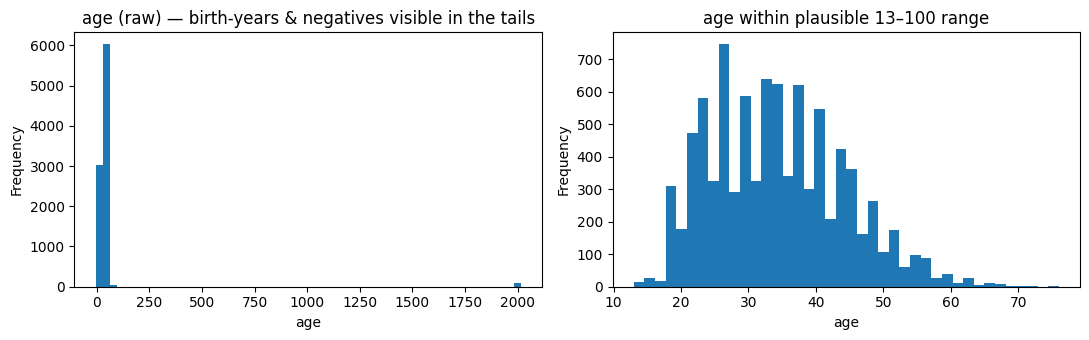

In [2]:
raw = data_prep.load_raw()
print(f"{len(raw):,} users, {raw['user_id'].nunique():,} unique ids")

# age summary — note the min/max and the missing count
display(raw["age"].describe())
print("missing age:", raw["age"].isna().sum())
print("implausible (<13 or >100):",
      int(((raw["age"] < data_prep.MIN_PLAUSIBLE_AGE) | (raw["age"] > data_prep.MAX_PLAUSIBLE_AGE)).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
raw["age"].plot.hist(bins=60, ax=ax[0])
ax[0].set_title("age (raw) — birth-years & negatives visible in the tails")
ax[0].set_xlabel("age")
raw.loc[raw["age"].between(data_prep.MIN_PLAUSIBLE_AGE, data_prep.MAX_PLAUSIBLE_AGE), "age"].plot.hist(bins=40, ax=ax[1])
ax[1].set_title("age within plausible 13–100 range")
ax[1].set_xlabel("age")
plt.tight_layout()
plt.show()

### B.2 — Cleaning applied to **all models** (Layer 1)

We separate two things that are often blurred:

- **Cleaning (Layer 1, here):** fixing what is *factually wrong* in the data. Identical for every model, applied **once, before the split**, so every model sees the same clean data.
- **Preprocessing (Layer 2, Part C):** scaling / encoding / imputation — *model-specific*, so it lives inside each model's `Pipeline` and is fit per-fold to avoid leakage. (The tree can ingest `NaN` directly; only the linear model needs ages imputed.)

**What we audited and deliberately left alone.** Beyond `age`, the dataset is pristine — 0 duplicate rows, 0 duplicate `user_id`, no leading/trailing whitespace, no case collisions, and no unexpected nulls (see cell output). We therefore apply **no** blanket text-cleaning: scrubbing columns that were never dirty adds risk for zero benefit.

**The only real repair — `age`.** 800 missing, 46 negatives, 28 child ages (1–12), and 96 birth-years (values up to 2014) — 170 implausible in all. Every bad value falls outside a plausible adult range **[13, 100]**, with *none* stranded in the 100–1900 gap, so the window cleanly separates real ages from data-entry errors. We **null** the implausible values (flag-then-null) rather than clip — clipping `-5 → 13` fabricates an age, whereas a null is honestly "unknown" and gets imputed later, per-model.

**Why keep missingness as a feature.** We keep `age_missing_or_invalid` rather than dropping the ~10% of affected users: *whether* a user's data is missing can itself correlate with booking, and dropping those rows would bias the sample. For consistency we also flag `gender = UNKNOWN` (14.7%, an upstream placeholder for missing) with `gender_missing`, while keeping `UNKNOWN` as a category so a model can still read it as "prefers not to say". _Open decision: the B.4 crosstab shows `UNKNOWN` converts at ~0.51, the same as everyone — so `gender_missing` may carry no signal. We revisit whether it earns its place after modelling._

**Representation, not cleaning — `signup_flow`.** Cast from int to categorical: `{0, 3, 12, 25}` are workflow codes, not magnitudes, so `25` must not be read as "8× more" than `3`.

In [3]:
# --- Layer 1: cleaning applied to ALL models (once, before the split) ---

# Audit first: is anything besides `age` actually dirty? (backs the 'no over-cleaning' claim)
text_cols = raw.select_dtypes("object").columns
print("duplicate rows:   ", raw.duplicated().sum())
print("duplicate user_id:", raw["user_id"].duplicated().sum())
print("whitespace-padded:", {c: int((raw[c] != raw[c].str.strip()).sum()) for c in text_cols})
print("nulls per column: ", raw.isna().sum().to_dict())

# Apply the shared cleaning + engineered missingness flags
clean = data_prep.prepare_features(raw)

print("\nafter cleaning:")
print("  age nulls (missing + nulled implausible):", clean["age"].isna().sum())
print("  age_missing_or_invalid rate:             ", round(clean["age_missing_or_invalid"].mean(), 3))
print("  gender_missing rate:                     ", round(clean["gender_missing"].mean(), 3))
print("  signup_flow dtype:                       ", clean["signup_flow"].dtype)

duplicate rows:    0
duplicate user_id: 0
whitespace-padded: {'user_id': 0, 'gender': 0, 'signup_method': 0, 'affiliate_channel': 0, 'first_device_type': 0, 'country_destination': 0}
nulls per column:  {'user_id': 0, 'age': 800, 'gender': 0, 'signup_method': 0, 'signup_flow': 0, 'affiliate_channel': 0, 'first_device_type': 0, 'country_destination': 0}

after cleaning:
  age nulls (missing + nulled implausible): 970
  age_missing_or_invalid rate:              0.097
  gender_missing rate:                      0.147
  signup_flow dtype:                        object


### B.3 — Stratified split & verification (representative / no-leakage evidence)
We split 70/15/15 **stratified on `country_destination`**, then verify it below: destination proportions stay steady across train/val/test, and no `user_id` appears in more than one split. Stratifying matters because the rarest class (`DE`, ~3%) could easily drift between splits under a plain random draw and distort the metrics — pinning every class's share keeps validation honest.

In [4]:
train, val, test = data_prep.make_splits(clean)

# representative? class proportions should be stable across splits
prop = pd.DataFrame({
    "train": train[data_prep.TARGET].value_counts(normalize=True),
    "val":   val[data_prep.TARGET].value_counts(normalize=True),
    "test":  test[data_prep.TARGET].value_counts(normalize=True),
}).round(3)
display(prop)

# no leakage across splits: user_id sets must be disjoint
ids = [set(d["user_id"]) for d in (train, val, test)]
overlap = (ids[0] & ids[1]) | (ids[0] & ids[2]) | (ids[1] & ids[2])
print("overlapping user_ids across splits:", len(overlap))

,train,val,test
country_destination,,,
NDF,0.482,0.483,0.483
US,0.197,0.197,0.197
other,0.080,0.079,0.079
ES,0.068,0.068,0.068
GB,0.052,0.053,0.053
IT,0.051,0.051,0.051
FR,0.043,0.043,0.043
DE,0.028,0.027,0.027


overlapping user_ids across splits: 0


### B.4 — EDA that generates hypotheses (feeds Part A §5)
Three quick probes, on **train only** (never peeking at val/test): **(H1)** does device or channel skew the top destination? **(H2)** does age relate to whether a user books? **(H3)** does the `gender = UNKNOWN` placeholder carry any booking signal worth keeping? The standout — every segment's most common destination is `US` — is what motivates the shortlist argument in Part A.

top non-NDF destination by first_device_type:


,top_destination,share
first_device_type,,
Android Phone,US,0.390
Mac Desktop,US,0.351
Windows Desktop,US,0.384
iPhone,US,0.427


top non-NDF destination by affiliate_channel:


,top_destination,share
affiliate_channel,,
direct,US,0.371
other,US,0.424
sem-brand,US,0.384
sem-non-brand,US,0.384


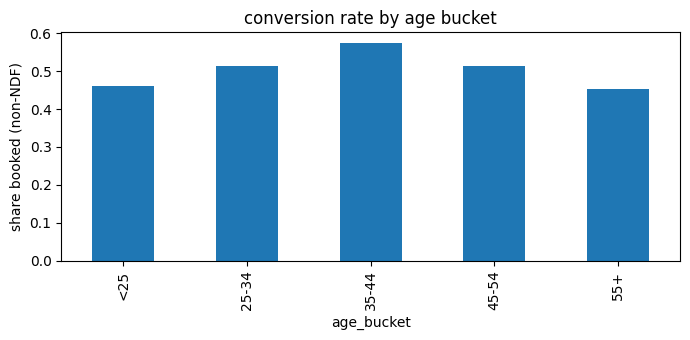

,flag_rate,conversion_when_flagged,conversion_when_clean
0,0.152286,0.511257,0.518874


gender
OTHER      0.560773
MALE       0.520856
FEMALE     0.511384
UNKNOWN    0.511257
Name: country_destination, dtype: float64

In [5]:
# EDA on TRAIN only (never peek at val/test) — generates Part A hypotheses.

# H1: does device or channel skew destinations? (non-NDF top pick per segment)
for seg in ["first_device_type", "affiliate_channel"]:
    print(f"top non-NDF destination by {seg}:")
    display(kpis.top_destination_per_segment(train, by=seg))

# H2: does age relate to booking? conversion by age bucket
train_b = kpis.add_age_bucket(train)
conv_by_age = kpis.conversion_rate(train_b, by="age_bucket")
ax = conv_by_age.sort_index().plot.bar(figsize=(7, 3.5), title="conversion rate by age bucket")
ax.set_ylabel("share booked (non-NDF)")
plt.tight_layout(); plt.show()

# H3: does gender_missing carry signal? (the crosstab that justifies keeping the flag)
display(kpis.data_trust_kpi(train, flag_col="gender_missing"))
display(kpis.conversion_rate(train, by="gender"))

### B.5 — Label ambiguity: how much is even knowable? (feeds Part A KPI choice)

Group users by their **discrete profile** — the categorical attributes + age band — and ask whether look-alike users actually book the same destination. This bounds how much of `country_destination` is *knowable* from the features we have, **before any model exists**. Computed on **train only** (no peeking at val/test).

**What this means.** Look-alike users — identical profile and age band — disagree on their actual destination **47%** of the time, so even a perfect memoriser of "what this exact profile usually books" tops out at **~57%** on a single guess. Two consequences follow:

- **(a) Why top-3 over top-1:** chasing a single best guess is fighting a ceiling the features simply can't break, so we rank a **top-3 shortlist** instead — the right answer can legitimately live in 2nd or 3rd place.
- **(b) Why "more data" is the real lever:** this ceiling is a *feature* limitation, not a model one. No amount of algorithm tuning breaks it — only richer signals (income, home location, prior trips) would, which is exactly the "extra data that would help" answer in Part A §5.

In [6]:
# Look-alike users = same categorical profile + same age band.
prof = kpis.add_age_bucket(train)
profile_cols = data_prep.CATEGORICAL_FEATURES + ["age_bucket"]
grp = prof.groupby(profile_cols, dropna=False, observed=True)["country_destination"]

n_profiles = grp.ngroups
ambiguous  = int((grp.nunique() > 1).sum())
rows_ambig = int(prof.duplicated(subset=profile_cols, keep=False).sum())
# oracle ceiling: predict each profile's most common destination
best_top1  = grp.apply(lambda s: s.value_counts().iloc[0]).sum() / len(prof)

print(f"distinct look-alike profiles:            {n_profiles}")
print(f"profiles with >1 actual destination:     {ambiguous} ({ambiguous / n_profiles:.0%})")
print(f"users sharing a profile with someone:    {rows_ambig} ({rows_ambig / len(prof):.0%})")
print(f"oracle max top-1 (memorise each profile's mode): {best_top1:.1%}")

distinct look-alike profiles:            1518
profiles with >1 actual destination:     718 (47%)
users sharing a profile with someone:    6314 (90%)
oracle max top-1 (memorise each profile's mode): 57.1%


---
# Part C — Models, Benchmarking & Explainability

### C.1 — Two-stage cascade: build the pipelines (leakage-safe)

A single 8-class model has to learn *whether* a user books **and** *where* at the same time — two questions that share little signal. We split them into a **cascade**:

- **Stage 1 (gate):** book vs `NDF` — binary.
- **Stage 2 (rank):** among the **7 real countries**, **trained on booked users only**. This is the leakage guard: if `NDF` rows leak into Stage 2, it learns to assign destinations to people who never book, and the top-3 number becomes fiction.

Both stages receive **all six features** — we do *not* hand-split funnel-vs-demographic inputs; SHAP (C.3) will tell us per stage which features actually mattered, turning that split from an assumption into evidence. Each stage gets a **baseline (`LogisticRegression`)** and a **gradient-boosted tree**, fit on train and tuned on val.

_The judgment calls, resolved:_ **`class_weight=None`** for both stages (Stage 1 is near-balanced so reweighting is moot; Stage 2 imbalance is handled by the top-3 + diversity metric, not by reweighting the loss — see comment below); **LightGBM** ships each stage and the Stage-1 **threshold** is set low (gate off by design) — both decided in **C.2** on the validation benchmark.

In [7]:
import warnings
import numpy as np
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

def make_pipe(estimator):
    """Leakage-safe: the preprocessor is fit INSIDE the pipeline, on train only."""
    return Pipeline([("prep", data_prep.build_preprocessor()), ("clf", estimator)])

def booked(df):
    """1 when the user booked (destination != NDF), else 0 — the Stage-1 target
    and the mask that keeps NDF rows out of Stage 2 (the leakage guard)."""
    return (df[data_prep.TARGET] != kpis.NDF_LABEL).astype(int)

Xtr,  _ = data_prep.get_X_y(train)      # all six features -> both stages (SHAP confirms the split)
Xval, _ = data_prep.get_X_y(val)

# Stage 2 = BOOKED ROWS ONLY (leakage guard), derived from the SAME split as Stage 1
train_booked = train[booked(train) == 1]
val_booked   = val[booked(val) == 1]
Xtr_b, ytr_b  = data_prep.get_X_y(train_booked)
Xval_b, yval_b = data_prep.get_X_y(val_booked)

# lbfgs on numpy 2.0 emits a spurious matmul RuntimeWarning; inputs verified finite.
with warnings.catch_warnings(), np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    warnings.simplefilter("ignore", RuntimeWarning)
    # Baseline vs. ONE tree, per stage. Same features + same split => the KPI gap is the MODEL.
    # class_weight=None for BOTH stages, for two different reasons:
    #   Stage 1 is ~52/48 (near-balanced), so reweighting a near-even split does essentially nothing.
    #   Stage 2 is imbalanced, but we rank on top-3 with a diversity veto -- the "don't just predict
    #   the majority" job is done by the METRIC, so reweighting the loss would be redundant (and could
    #   even fight the diversity goal by over-inflating rare classes).
    stage1 = {
        "LogReg":   make_pipe(LogisticRegression(max_iter=1000, class_weight=None)).fit(Xtr, booked(train)),
        "LightGBM": make_pipe(LGBMClassifier(random_state=42, verbose=-1)).fit(Xtr, booked(train)),
    }
    stage2 = {
        "LogReg":   make_pipe(LogisticRegression(max_iter=1000, class_weight=None)).fit(Xtr_b, ytr_b),
        "LightGBM": make_pipe(LGBMClassifier(random_state=42, verbose=-1)).fit(Xtr_b, ytr_b),
    }

assert "NDF" not in set(ytr_b), "NDF leaked into Stage 2!"
print("Stage 1 models:", list(stage1), "| target: book vs NDF")
print("Stage 2 models:", list(stage2), "| classes:", list(stage2["LightGBM"].classes_))
print("booked rows (train/val):", len(train_booked), "/", len(val_booked))

Stage 1 models: ['LogReg', 'LightGBM'] | target: book vs NDF
Stage 2 models: ['LogReg', 'LightGBM'] | classes: ['DE', 'ES', 'FR', 'GB', 'IT', 'US', 'other']
booked rows (train/val): 3624 / 776


### C.2 — Benchmark & rank (select on **val**, report on **test** once)

Models are selected on the **validation** set; the shipped pair is reported **once** on test.
**Stage 1** ranks by **PR-AUC** (threshold-free). **Stage 2** ranks by **top-3 accuracy** with a
**diversity@1 veto** — a model that wins top-1 by recommending the same destination to everyone is
*not* personalizing, so it loses even at higher top-1.

## Model & threshold decisions

**Stage 1 (will they book?): LightGBM**
LightGBM wins PR-AUC on both validation (0.569) and test (0.570) — the metric we committed
to before looking at results, and the right one given the near-balanced (~52/48) class split.
The margin over logistic regression is small but consistent across both splits. Because PR-AUC
already balances precision and recall in a threshold-free way, it's the honest basis for the
call; concretely, LightGBM buys higher recall (it catches more true bookers) at essentially
equal precision on test, for only a slight precision give-up on validation.

**Stage 2 (which of 7 countries?): LightGBM, via a diversity veto**
Logistic regression posts a higher top-1 accuracy (0.379), but it earns that score by
recommending only 4 of the 7 countries, with 91% of all recommendations funneled into a single
destination. That's not a model that understands travelers — it's a model that learned the
prior. LightGBM's top-1 is lower, but it recommends across all 7 countries and wins decisively
on top-3 accuracy (0.784), which is the metric the product actually surfaces to users (a
3-option shortlist, not a single guess). We're vetoing top-1 as the deciding metric because it
rewards popularity-matching over genuine ranking, and selecting LightGBM on top-3, where the
result also holds on test.

**Stage 1 threshold: low — gate off by design**
Rather than picking a threshold that maximizes precision, we're setting the bar low enough to
personalize essentially everyone. A wasted personalization slot (showing tailored country
suggestions to someone who wasn't going to book) costs very little. A missed booking — failing
to personalize for someone who would have booked — costs far more. Given that asymmetry, the
probability score should act as a *priority signal* for ranking or resourcing, not a *gate*
that hides the feature from lower-confidence users.

_Sanity check (see C.2b below): the shipped Stage-2 top-1 on test is 0.336 — comfortably below
the ~0.57 look-alike oracle ceiling from B.5, so the ranking reflects real signal, not leakage._

In [8]:
import pandas as pd
import warnings

yval_book = booked(val)

# predict_proba on the LR pipelines re-triggers the benign numpy-2.0 matmul warning, and LightGBM
# emits a cosmetic feature-names UserWarning inside a Pipeline; inputs are verified, so silence both.
with warnings.catch_warnings(), np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    warnings.simplefilter("ignore")

    # ---- Stage 1: rank by PR-AUC (book vs NDF), all rows ----
    stage1_bench = pd.DataFrame([
        {"model": name, **kpis.booking_metrics(yval_book, m.predict_proba(Xval)[:, 1])
                             .set_index("metric")["value"].to_dict()}
        for name, m in stage1.items()
    ]).set_index("model").round(3)

    stage1_gate = kpis.confidence_coverage(
        yval_book, stage1["LightGBM"].predict_proba(Xval), stage1["LightGBM"].classes_).round(3)

    # ---- Stage 2: rank by top-3, diversity@1 as veto (booked rows only) ----
    stage2_rows = []
    for name, m in stage2.items():
        proba, classes = m.predict_proba(Xval_b), m.classes_
        div = kpis.diversity_at_1(classes[proba.argmax(1)], n_possible=7).set_index("metric")["value"]
        stage2_rows.append({
            "model": name,
            "top1": kpis.top_k_accuracy(yval_b, proba, classes, k=1),
            "top3": kpis.top_k_accuracy(yval_b, proba, classes, k=3),
            "diversity_entropy": div["diversity_entropy"],
            "top_dest_share": div["top_dest_share"],
            "distinct_recommended": div["distinct_recommended"],
        })
    stage2_bench = pd.DataFrame(stage2_rows).set_index("model").round(3)

print("STAGE 1 — book vs NDF (rank by pr_auc):");                 display(stage1_bench)
print("Stage-1 confidence/coverage sweep (pick your threshold):"); display(stage1_gate)
print("STAGE 2 — which destination? (rank by top3; diversity veto):"); display(stage2_bench)

STAGE 1 — book vs NDF (rank by pr_auc):


,pr_auc,precision@0.5,recall@0.5
model,,,
LogReg,0.552,0.540,0.535
LightGBM,0.569,0.528,0.563


Stage-1 confidence/coverage sweep (pick your threshold):


,threshold,coverage,precision_within_covered
0,0.3,1.000,0.513
1,0.4,1.000,0.513
2,0.5,1.000,0.513
3,0.6,0.347,0.559
4,0.7,0.125,0.633
5,0.8,0.023,0.706


STAGE 2 — which destination? (rank by top3; diversity veto):


,top1,top3,diversity_entropy,top_dest_share,distinct_recommended
model,,,,,
LogReg,0.380,0.776,0.194,0.91,4.0
LightGBM,0.318,0.786,0.756,0.55,7.0


### C.2b — Final report on the held-out **test** set (once)

Models were **chosen on validation** (C.2 above). Here we look at the **test** set a
single time, for the shipped baseline-vs-LightGBM pair — **no tuning happens after this
number is seen**. The table mirrors the val benchmark exactly so the two are directly
comparable:

- **Stage 1** — scored on *all* test rows, ranked by **PR-AUC** (honest under the ~52/48 split).
- **Stage 2** — scored on **booked rows only** (the leakage guard), ranked by **top-3**
  with the **diversity@1** veto.

Two sanity checks when reading it: if **test tracks val**, the cascade isn't overfit; if
**Stage-2 top-1 exceeds the ~0.57 oracle ceiling** from B.5, that's leakage, not skill.

In [9]:
# ---- FINAL TEST-SET REPORT (shipped pair) — computed ONCE, no re-tuning after this ----
# Models were already fit on TRAIN (C.1) and selected on VAL (C.2). We now score the SAME
# fitted models on the held-out TEST set. Mirrors C.2 exactly so val<->test are comparable.
Xtest, _ = data_prep.get_X_y(test)
ytest_book = booked(test)

# Stage 2 = booked test rows only (same leakage guard as train/val)
test_booked = test[booked(test) == 1]
Xtest_b, ytest_b = data_prep.get_X_y(test_booked)

with warnings.catch_warnings(), np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    warnings.simplefilter("ignore")

    # ---- Stage 1 on ALL test rows: baseline vs shipped, rank by PR-AUC ----
    stage1_test = pd.DataFrame([
        {"model": name, **kpis.booking_metrics(ytest_book, m.predict_proba(Xtest)[:, 1])
                             .set_index("metric")["value"].to_dict()}
        for name, m in stage1.items()
    ]).set_index("model").round(3)

    # ---- Stage 2 on BOOKED test rows: baseline vs shipped, top-3 + diversity veto ----
    stage2_test_rows = []
    for name, m in stage2.items():
        proba, classes = m.predict_proba(Xtest_b), m.classes_
        div = kpis.diversity_at_1(classes[proba.argmax(1)], n_possible=7).set_index("metric")["value"]
        stage2_test_rows.append({
            "model": name,
            "top1": kpis.top_k_accuracy(ytest_b, proba, classes, k=1),
            "top3": kpis.top_k_accuracy(ytest_b, proba, classes, k=3),
            "diversity_entropy": div["diversity_entropy"],
            "top_dest_share": div["top_dest_share"],
            "distinct_recommended": div["distinct_recommended"],
        })
    stage2_test = pd.DataFrame(stage2_test_rows).set_index("model").round(3)

print("TEST — Stage 1 (book vs NDF), all test rows:"); display(stage1_test)
print(f"TEST — Stage 2 (which destination), booked rows only (n={len(test_booked)});")
print("       sanity: shipped top1 must stay BELOW the ~0.571 B.5 oracle ceiling (else leakage).")
display(stage2_test)

TEST — Stage 1 (book vs NDF), all test rows:


,pr_auc,precision@0.5,recall@0.5
model,,,
LogReg,0.568,0.548,0.532
LightGBM,0.570,0.547,0.564


TEST — Stage 2 (which destination), booked rows only (n=776);
       sanity: shipped top1 must stay BELOW the ~0.571 B.5 oracle ceiling (else leakage).


,top1,top3,diversity_entropy,top_dest_share,distinct_recommended
model,,,,,
LogReg,0.379,0.750,0.191,0.912,4.0
LightGBM,0.336,0.784,0.769,0.536,7.0


### C.3 — Explainability (SHAP): magnitude **and** direction

Bar plots rank features by *magnitude*; **beeswarm** and **dependence** plots add *direction*
(red = high feature value; left/right = which way it pushes the prediction). Stage-2 plots are
relabelled with real destinations and axis labels are stripped of `num__/cat__` prefixes so a
non-technical reviewer can read them. All figures save to `../reports/figures/`.

## What drives the predictions

**1. Device type is a proxy, not a cause — and it's a fairness flag**
`first_device_type_Mac Desktop` is the #1 or #2 driver of predictions in *both* stages. Read
literally, this says "Mac users book more and book differently." But device type isn't a
meaningful causal factor in travel behavior — it's a proxy for affluence and, likely, Western
geography. Two implications follow:

- **Business implication:** if we let this feature drive *who gets personalized* (Stage-1 gating),
  we risk systematically under-serving non-Mac users — the opposite of what personalization
  should do.
- **Action:** use it to *rank* suggestions within an already-personalized experience, not to
  decide *whether* someone gets personalized. Longer term, we should collect real income/location
  features so the model isn't relying on a device proxy for something it can't observe directly.

**2. Age: younger users rarely book**
In Stage 1, low age consistently pushes predictions *away* from booking (clear in the beeswarm
and the age-dependence plot). This isn't just a modeling curiosity — it's an acquisition/
onboarding signal. Rather than personalizing destination recommendations for young users at the
same intensity as older users, this segment may be better served by a different early-funnel
experience (e.g., lower-commitment content, inspiration browsing) before we push destination
personalization at them. *(We keep the age story to Stage 1, where the direction is unambiguous;
in Stage 2 the age effect is non-monotonic, so we don't over-read it.)*

**3. Signup flow does not drive destination — the funnel hypothesis is refuted**
Going in, one hypothesis was that *how* a user signed up (e.g., which signup flow/channel)
would meaningfully shape *where* they end up traveling. `signup_flow` sits near zero in the
importance bar chart for both stages. The data doesn't support this hypothesis, and we're
reporting that explicitly rather than omitting it — a clean negative result is still a result,
and it tells us not to invest further in signup-flow-based targeting for destination
recommendations.

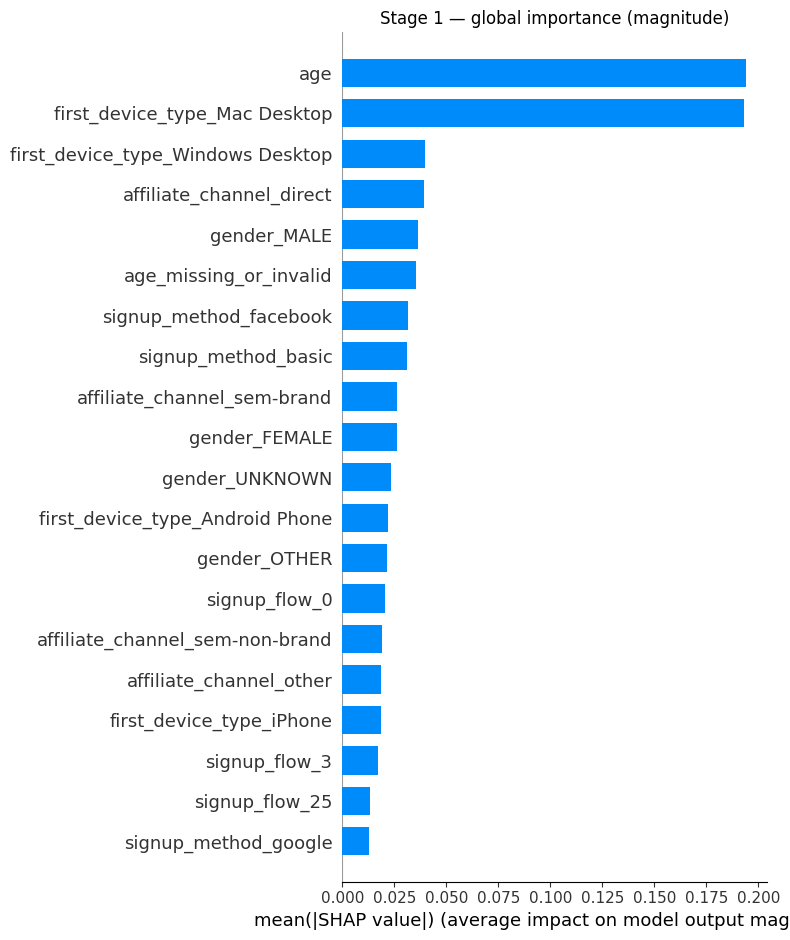

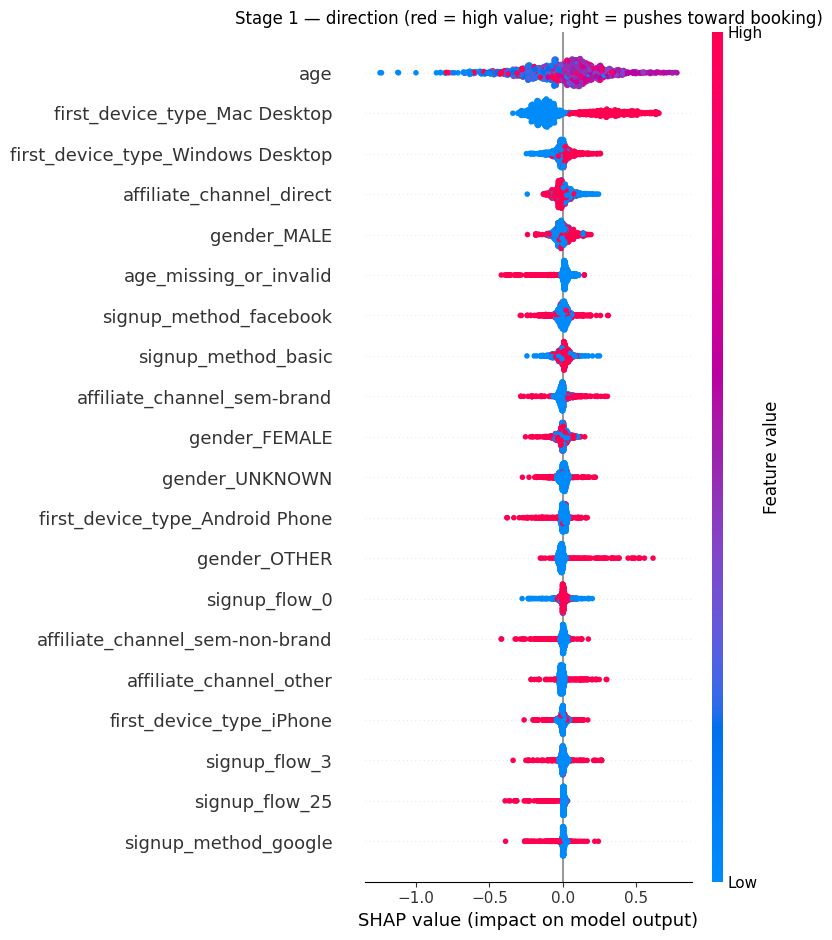

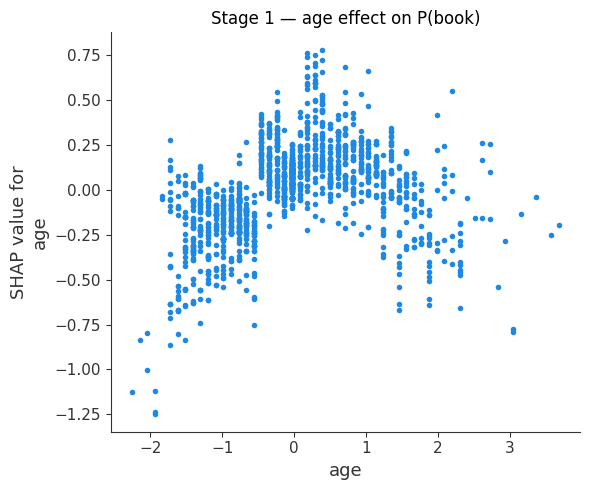

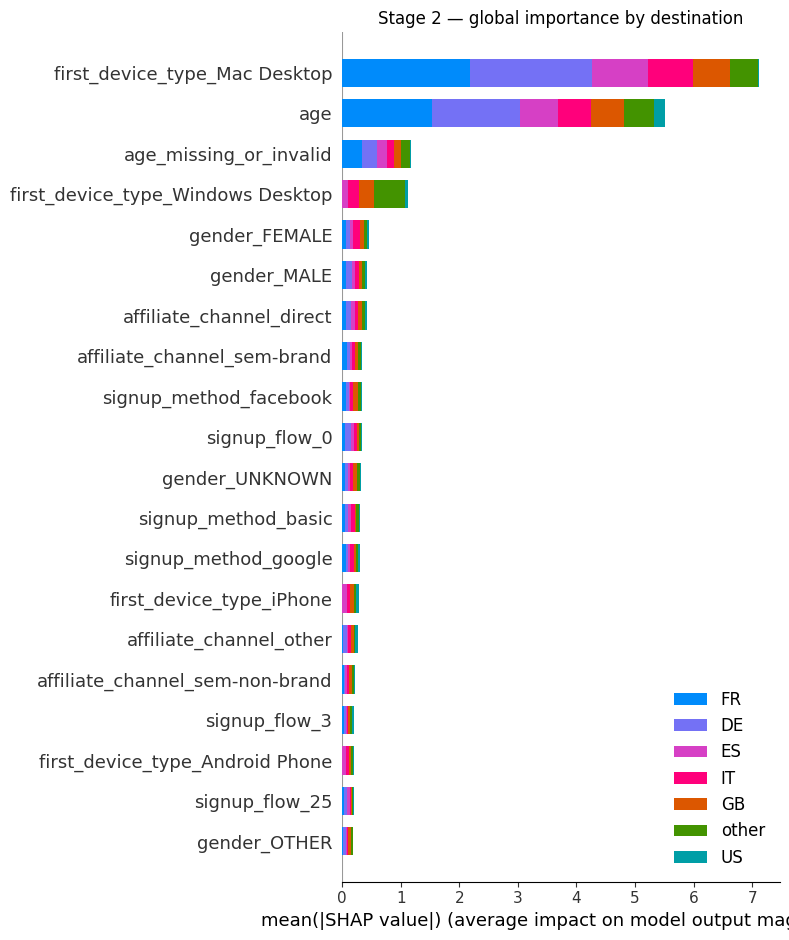

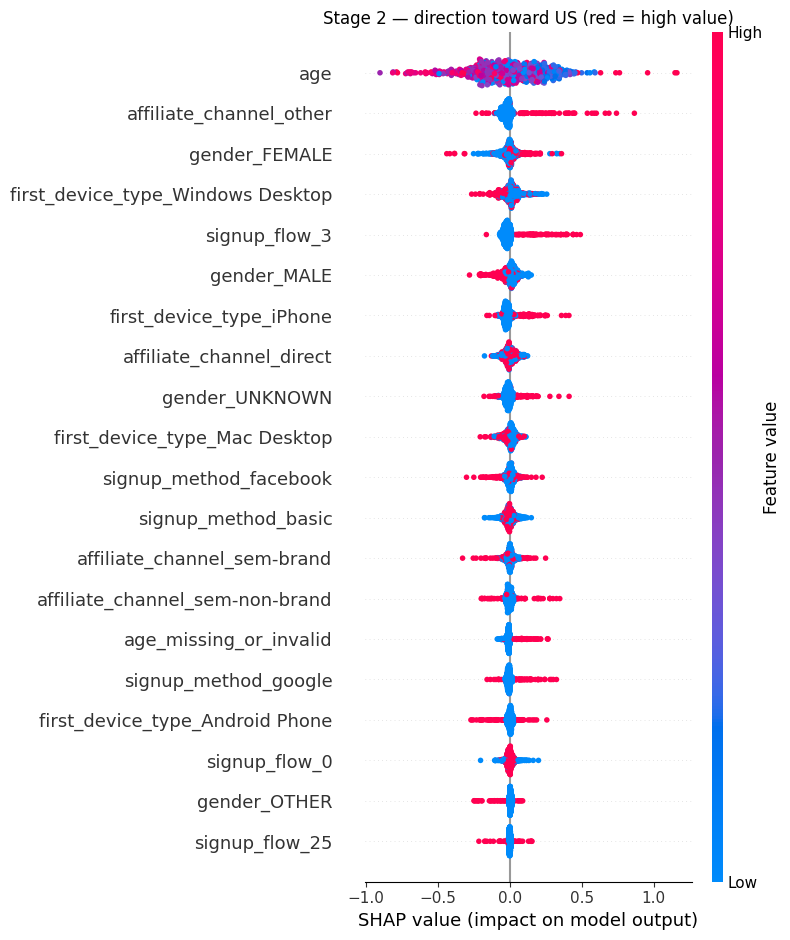

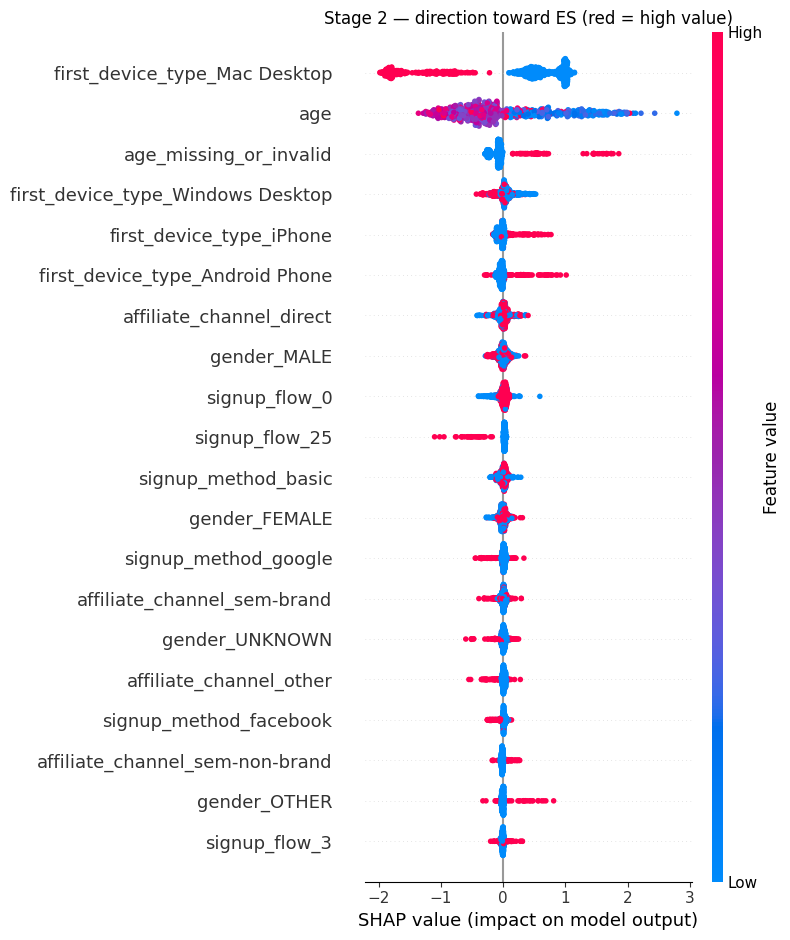

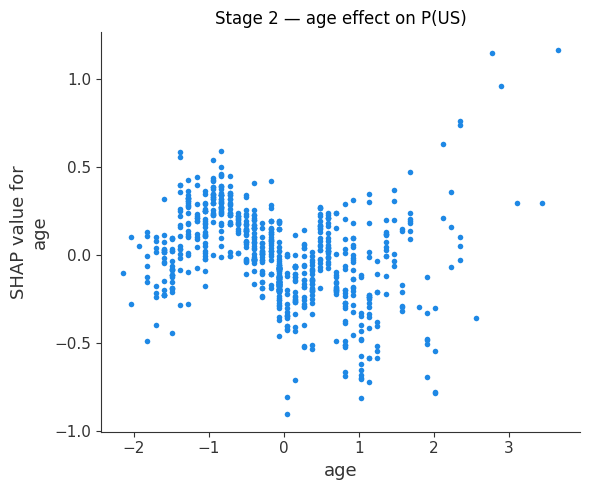

In [10]:
import matplotlib.pyplot as plt
import shap
import warnings
from pathlib import Path

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

def _clean(names):
    """Drop ColumnTransformer prefixes (num__/cat__/passthrough__) for a business reader."""
    return [n.split("__", 1)[1] if "__" in n else n for n in names]

def _explain(pipe, X):
    """Return (classifier, dense transformed matrix, clean feature names, shap values)."""
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    Xt = prep.transform(X)
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
    names = _clean(list(prep.get_feature_names_out()))
    return clf, Xt, names, shap.TreeExplainer(clf).shap_values(Xt)

def _save(fname):
    plt.tight_layout(); plt.savefig(FIG / fname, dpi=90, bbox_inches="tight"); plt.show(); plt.close()

with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")

    # ===== Stage 1: will they book? (binary) =====
    clf, Xt, names, sv = _explain(stage1["LightGBM"], Xval)
    shap.summary_plot(sv, Xt, feature_names=names, plot_type="bar", show=False)
    plt.title("Stage 1 — global importance (magnitude)"); _save("shap_stage1_bar.png")
    shap.summary_plot(sv, Xt, feature_names=names, show=False)  # beeswarm = DIRECTION
    plt.title("Stage 1 — direction (red = high value; right = pushes toward booking)")
    _save("shap_stage1_beeswarm.png")
    shap.dependence_plot(names.index("age"), sv, Xt, feature_names=names,
                         interaction_index=None, show=False)
    plt.title("Stage 1 — age effect on P(book)"); _save("shap_stage1_age_dep.png")

    # ===== Stage 2: which destination? (multiclass, booked only) =====
    clf, Xt, names, sv = _explain(stage2["LightGBM"], Xval_b)
    shap.summary_plot(sv, Xt, feature_names=names, plot_type="bar",
                      class_names=list(clf.classes_), show=False)  # relabelled DE/ES/...
    plt.title("Stage 2 — global importance by destination"); _save("shap_stage2_bar.png")
    for dest in ["US", "ES"]:  # a big market vs. a small market — is the driver the same?
        ci = list(clf.classes_).index(dest)
        shap.summary_plot(sv[:, :, ci], Xt, feature_names=names, show=False)
        plt.title(f"Stage 2 — direction toward {dest} (red = high value)")
        _save(f"shap_stage2_{dest}_beeswarm.png")
    ci_us = list(clf.classes_).index("US")
    shap.dependence_plot(names.index("age"), sv[:, :, ci_us], Xt, feature_names=names,
                         interaction_index=None, show=False)
    plt.title("Stage 2 — age effect on P(US)"); _save("shap_stage2_age_dep.png")